In [ ]:
# 1. Імпортуємо необхідні бібліотеки
from google.colab import auth
from google.cloud import bigquery
import pandas as pd

# 2. Авторизуємося в Google-акаунті
auth.authenticate_user()

# 3. Створюємо підключення до BigQuery (клієнт)
client = bigquery.Client(project='data-analytics-mate')

print("Підключення до BigQuery успішно встановлено!")

Підключення до BigQuery успішно встановлено!


In [ ]:
# SQL-запит для об'єднання всіх необхідних таблиць
query = """
SELECT
    s.date AS session_date,
    s.ga_session_id,
    sp.continent,
    sp.country,
    sp.device,
    sp.browser,
    sp.mobile_model_name,
    sp.operating_system,
    sp.language,
    sp.medium,
    sp.name AS traffic_source_name,
    sp.channel,
    a.id AS user_id,
    a.is_verified,
    a.is_unsubscribed,
    p.category AS product_category,
    p.name AS product_name,
    p.price,
    p.short_description
FROM `data-analytics-mate.DA.session` AS s
LEFT JOIN `data-analytics-mate.DA.session_params` AS sp
    ON s.ga_session_id = sp.ga_session_id
LEFT JOIN `data-analytics-mate.DA.account_session` AS acc_sess
    ON s.ga_session_id = acc_sess.ga_session_id
LEFT JOIN `data-analytics-mate.DA.account` AS a
    ON acc_sess.account_id = a.id
LEFT JOIN `data-analytics-mate.DA.order` AS o
    ON s.ga_session_id = o.ga_session_id
LEFT JOIN `data-analytics-mate.DA.product` AS p
    ON o.item_id = p.item_id
"""

# Виконуємо запит з вимкненим BQ Storage API (щоб оминути обмеження прав)
df = client.query(query).to_dataframe(create_bqstorage_client=False)

# Перевіряємо результат
print("Датасет успішно створено!")
print(f"Кількість рядків: {df.shape[0]}, Кількість колонок: {df.shape[1]}")
df.head()

Датасет успішно створено!
Кількість рядків: 349545, Кількість колонок: 19


,session_date,ga_session_id,continent,country,device,browser,mobile_model_name,operating_system,language,medium,traffic_source_name,channel,user_id,is_verified,is_unsubscribed,product_category,product_name,price,short_description
0,2020-11-01,967742695,Americas,United States,desktop,Safari,Safari,Web,en-us,(data deleted),(data deleted),Undefined,<NA>,<NA>,<NA>,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"
1,2020-11-01,9065007548,Asia,China,desktop,Chrome,Safari,Web,None,(data deleted),(data deleted),Undefined,<NA>,<NA>,<NA>,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"
2,2020-11-01,3267062634,Americas,United States,desktop,Chrome,Safari,Web,en-us,(data deleted),(data deleted),Undefined,<NA>,<NA>,<NA>,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"
3,2020-11-01,8892952409,Americas,United States,mobile,Android Webview,<Other>,Web,ko,(data deleted),(data deleted),Undefined,<NA>,<NA>,<NA>,None,None,NaN,None
4,2020-11-01,1624570787,Asia,Turkey,desktop,<Other>,<Other>,Web,en-us,(data deleted),(data deleted),Undefined,<NA>,<NA>,<NA>,None,None,NaN,None


In [ ]:
import pandas as pd

# 1. Приведення дати до типу datetime
df['session_date'] = pd.to_datetime(df['session_date'])

# 2. Розподіл колонок за типами даних
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = df.select_dtypes(include=['object', 'category', 'string']).columns.tolist()
date_cols = df.select_dtypes(include=['datetime64[ns]', 'datetime']).columns.tolist()

# 3. Базові метрики датасету
print("="*50)
print("     ОПИС ОПРИМАНОГО ДАТАСЕТУ (EXPLORATORY ANALYSIS)")
print("="*50)
print(f"1. Загальна кількість рядків: {df.shape[0]:,}")
print(f"2. Загальна кількість колонок: {df.shape[1]}")

print(f"\n3. Числові колонки ({len(num_cols)}):")
print(f"   {num_cols}")

print(f"\n4. Категоріальні колонки ({len(cat_cols)}):")
print(f"   {cat_cols}")

print(f"\n5. Колонки типу datetime ({len(date_cols)}):")
print(f"   {date_cols}")

# 4. Унікальні сесії та часовий період
unique_sessions = df['ga_session_id'].nunique()
min_date = df['session_date'].min().strftime('%Y-%m-%d')
max_date = df['session_date'].max().strftime('%Y-%m-%d')

print(f"\n6. Кількість унікальних сесій: {unique_sessions:,}")
print(f"7. Період часу: від {min_date} до {max_date}")

# 5. Аналіз пропущених значень (Null / NaN)
print("\n"+"="*50)
print("     АНАЛІЗ ПРОПУЩЕНИХ ЗНАЧЕНЬ (MISSING VALUES)")
print("="*50)

null_counts = df.isnull().sum()
null_percent = (df.isnull().sum() / len(df)) * 100

null_df = pd.DataFrame({
    'Пропущено (шт)': null_counts,
    'Відсоток пропусків (%)': null_percent.round(2)
})

# Виводимо лише ті колонки, де є пропущені значення
missing_data = null_df[null_df['Пропущено (шт)'] > 0].sort_values(by='Пропущено (шт)', ascending=False)
print(missing_data)

# 6. Власна перевірка: наявність 'data deleted' в категоріальних полях
print("\n"+"="*50)
print("     ДОДАТКОВІ ІНСАЙТИ ЩОДО ЯКОСТІ ДАНИХ")
print("="*50)
print(f"Значень 'data deleted' у medium: {(df['medium'] == 'data deleted').sum():,}")
print(f"Значень 'data deleted' у traffic_source_name: {(df['traffic_source_name'] == 'data deleted').sum():,}")

     ОПИС ОПРИМАНОГО ДАТАСЕТУ (EXPLORATORY ANALYSIS)
1. Загальна кількість рядків: 349,545
2. Загальна кількість колонок: 19

3. Числові колонки (5):
   ['ga_session_id', 'user_id', 'is_verified', 'is_unsubscribed', 'price']

4. Категоріальні колонки (13):
   ['continent', 'country', 'device', 'browser', 'mobile_model_name', 'operating_system', 'language', 'medium', 'traffic_source_name', 'channel', 'product_category', 'product_name', 'short_description']

5. Колонки типу datetime (1):
   ['session_date']

6. Кількість унікальних сесій: 349,545
7. Період часу: від 2020-11-01 до 2021-01-31

     АНАЛІЗ ПРОПУЩЕНИХ ЗНАЧЕНЬ (MISSING VALUES)
                   Пропущено (шт)  Відсоток пропусків (%)
user_id                    321600                   92.01
is_verified                321600                   92.01
is_unsubscribed            321600                   92.01
product_category           316007                   90.41
price                      316007                   90.41
product

## Опис отриманого датасету

Датасет містить 349 545 рядків та 19 колонок. Дані охоплюють період з 1 листопада 2020 року по 31 січня 2021 року (3 місяці). Кожен рядок відповідає унікальній сесії користувача.

Розподіл типів даних:
* 5 числових колонок (ga_session_id, user_id, is_verified, is_unsubscribed, price)
* 13 категоріальних колонок (continent, country, device, browser, mobile_model_name, operating_system, language, medium, traffic_source_name, channel, product_category, product_name, short_description)
* 1 колонка типу datetime (session_date)

Аналіз пропущених значень та їх причини:
* Поля акаунту (user_id, is_verified, is_unsubscribed) мають 92.01% пропусків, оскільки більшість відвідувачів незареєстровані.
* Поля товарів (product_category, price, product_name, short_description) мають 90.41% пропусків, оскільки вони заповнюються лише при покупці. Розрахована конверсія сесій у покупку становить 9.59%.
* Мова браузера (language) пропущена у 32.69% сесій.

Якість даних та джерела трафіку:
* Поля medium та traffic_source_name містять реальний розподіл трафіку, де переважають organic та direct.
* Значення (data deleted) становлять лише 6.2% від усіх сесій. Для подальшого аналізу зручно використовувати агреговане поле channel.

1. ТОП-3 КОНТИНЕНТИ ТА ТОП-5 КРАЇН ЗА ПРОДАЖАМИ І ЗАМОВЛЕННЯМИ

--- Топ-3 континенти ---
           total_revenue  total_orders
continent                             
Americas      17665280.0         18553
Asia           7601298.3          7950
Europe         5934624.2          6261

--- Топ-5 країн ---
                total_revenue  total_orders
country                                    
United States      13943553.9         14673
India               2809762.0          3029
Canada              2437921.0          2560
United Kingdom       938317.9          1029
France               710692.8           678

2. ТОП-10 КАТЕГОРІЙ ТОВАРІВ (ВСЬОГО ТА У КРАЇНІ №1)
--- Топ-10 категорій по світу ---
product_category
Sofas & armchairs                   8388254.5
Chairs                              6147748.8
Beds                                4919725.0
Bookcases & shelving units          3640818.1
Cabinets & cupboards                2336499.5
Outdoor furniture                   2142222.2
Tables 

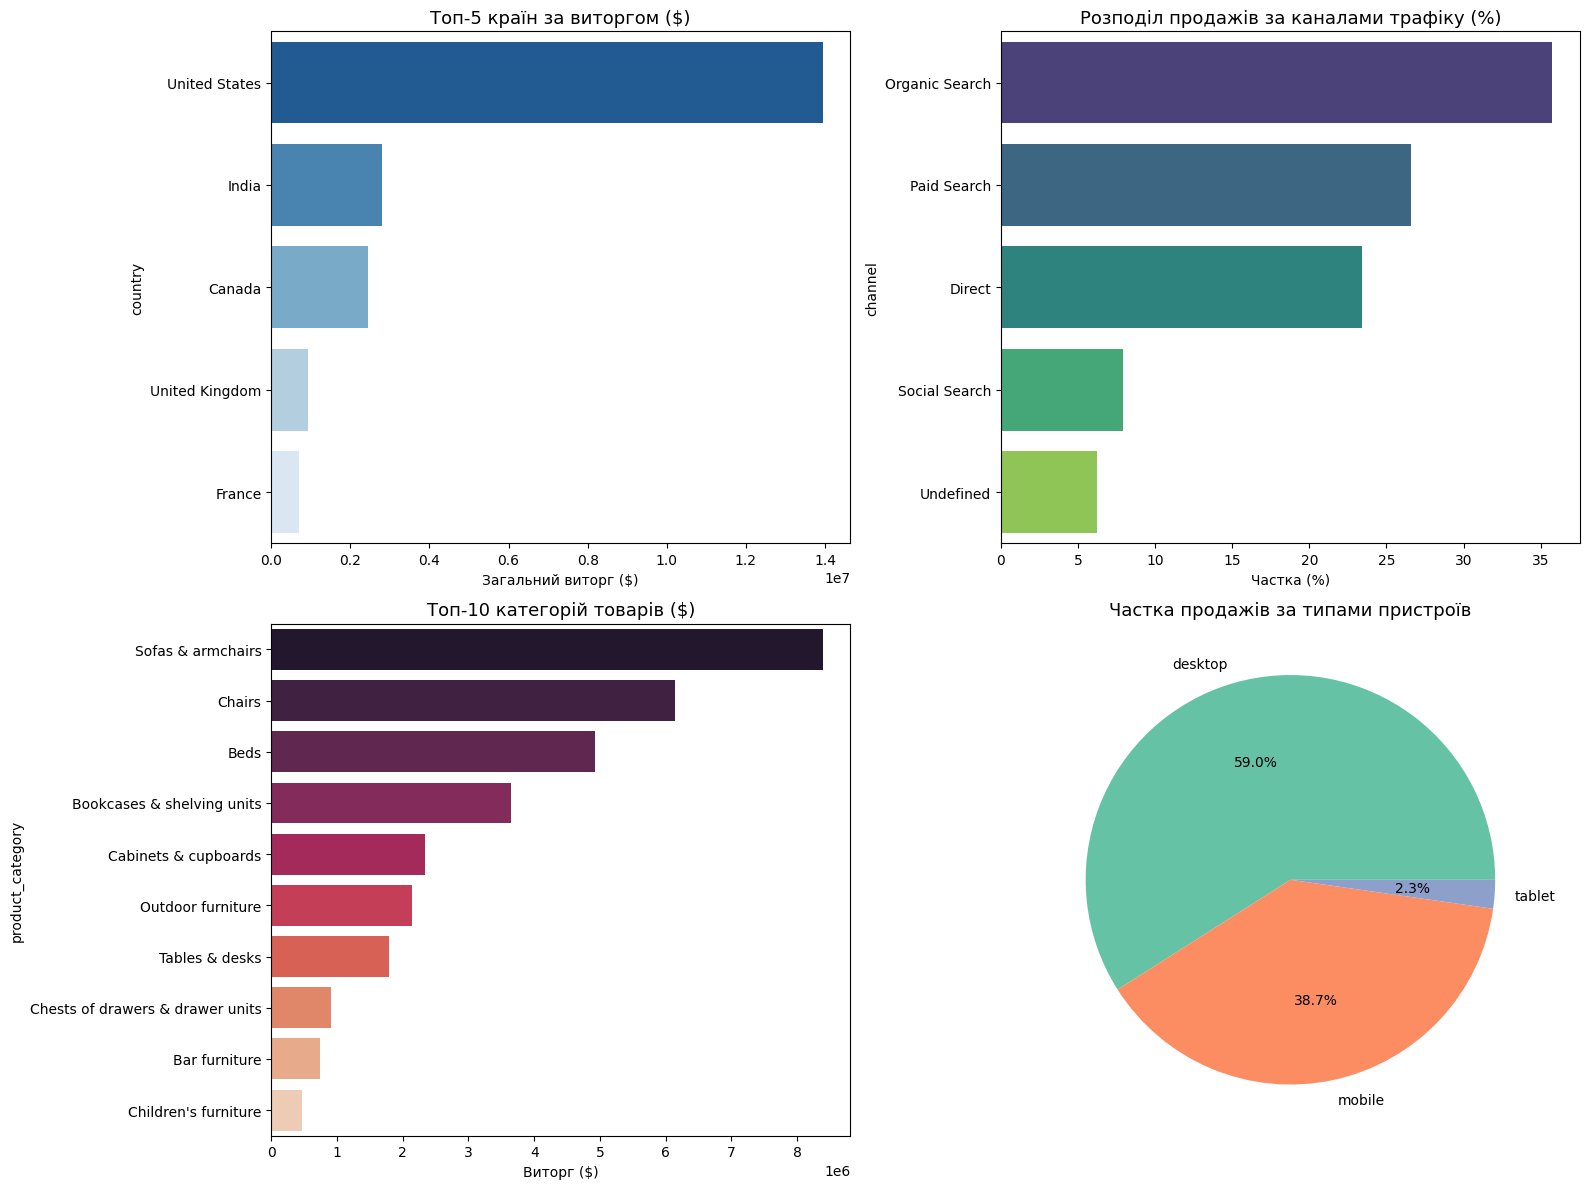

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# ---------------------------------------------------------
# 1. ТЕКСТОВИЙ ВИВІД ТОЧНИХ МЕТРИК
# ---------------------------------------------------------
print("="*65)
print("1. ТОП-3 КОНТИНЕНТИ ТА ТОП-5 КРАЇН ЗА ПРОДАЖАМИ І ЗАМОВЛЕННЯМИ")
print("="*65)
cont_sales = df.groupby('continent').agg(
    total_revenue=('price', 'sum'),
    total_orders=('price', 'count')
).sort_values(by='total_revenue', ascending=False)

print("\n--- Топ-3 континенти ---")
print(cont_sales.head(3))

country_sales = df.groupby('country').agg(
    total_revenue=('price', 'sum'),
    total_orders=('price', 'count')
).sort_values(by='total_revenue', ascending=False)

print("\n--- Топ-5 країн ---")
print(country_sales.head(5))


print("\n" + "="*65)
print("2. ТОП-10 КАТЕГОРІЙ ТОВАРІВ (ВСЬОГО ТА У КРАЇНІ №1)")
print("="*65)
top_categories = df.groupby('product_category')['price'].sum().sort_values(ascending=False).head(10)
print("--- Топ-10 категорій по світу ---")
print(top_categories)

top_1_country = country_sales.index[0]
top_country_categories = df[df['country'] == top_1_country].groupby('product_category')['price'].sum().sort_values(ascending=False).head(10)
print(f"\n--- Топ-10 категорій у країні-лідері ({top_1_country}) ---")
print(top_country_categories)


print("\n" + "="*65)
print("3. ПРОДАЖІ ЗА ПРИСТРОЯМИ ТА КАНАЛАМИ ТРАФІКУ (%)")
print("="*65)
device_sales_pct = (df.groupby('device')['price'].sum() / df['price'].sum() * 100).round(2).sort_values(ascending=False)
channel_sales_pct = (df.groupby('channel')['price'].sum() / df['price'].sum() * 100).round(2).sort_values(ascending=False)

print("--- Продажі за девайсами (%) ---")
print(device_sales_pct)

print("\n--- Продажі за каналами трафіку (%) ---")
print(channel_sales_pct)


print("\n" + "="*65)
print("4. МЕТРИКИ ЗАРЕЄСТРОВАНИХ КОРИСТУВАЧІВ")
print("="*65)
registered_users = df[df['user_id'].notnull()].drop_duplicates(subset=['user_id'])
total_reg = len(registered_users)
verified_pct = (registered_users['is_verified'].sum() / total_reg * 100) if total_reg > 0 else 0
unsubscribed_pct = (registered_users['is_unsubscribed'].sum() / total_reg * 100) if total_reg > 0 else 0

print(f"Загалом унікальних зареєстрованих користувачів: {total_reg}")
print(f"Відсоток підтверджених email: {verified_pct:.2f}%")
print(f"Відсоток відписаних від розсилки: {unsubscribed_pct:.2f}%")

reg_df = df[df['user_id'].notnull()]
sub_behavior = reg_df.groupby('is_unsubscribed').agg(
    total_sales=('price', 'sum'),
    avg_order_value=('price', 'mean'),
    orders_count=('price', 'count')
)
sub_behavior.index = ['Підписані (0)', 'Відписані (1)']
print("\n--- Поведінка підписаних vs відписаних користувачів ---")
print(sub_behavior)


# ---------------------------------------------------------
# 2. ВІЗУАЛІЗАЦІЯ (БЕЗ ПОМИЛОК SEABORN)
# ---------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Графік 1: Топ-5 країн
sns.barplot(
    x=country_sales.head(5).total_revenue,
    y=country_sales.head(5).index,
    hue=country_sales.head(5).index,
    palette="Blues_r",
    legend=False,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Топ-5 країн за виторгом ($)", fontsize=13)
axes[0, 0].set_xlabel("Загальний виторг ($)")

# Графік 2: Продажі за каналами
sns.barplot(
    x=channel_sales_pct.values,
    y=channel_sales_pct.index,
    hue=channel_sales_pct.index,
    palette="viridis",
    legend=False,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Розподіл продажів за каналами трафіку (%)", fontsize=13)
axes[0, 1].set_xlabel("Частка (%)")

# Графік 3: Топ-10 категорій
sns.barplot(
    x=top_categories.values,
    y=top_categories.index,
    hue=top_categories.index,
    palette="rocket",
    legend=False,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Топ-10 категорій товарів ($)", fontsize=13)
axes[1, 0].set_xlabel("Виторг ($)")

# Графік 4: Частка за пристроями
axes[1, 1].pie(
    device_sales_pct,
    labels=device_sales_pct.index,
    autopct='%1.1f%%',
    colors=sns.color_palette("Set2", len(device_sales_pct))
)
axes[1, 1].set_title("Частка продажів за типами пристроїв", fontsize=13)

plt.tight_layout()
plt.show()

# Підсумкові висновки за результатами аналізу даних

## 1. Географія продажів

**Континенти-лідери:**
- **Americas (Північна та Південна Америка):** Абсолютний лідер за виторгом (\$17,665,280.0) та кількістю замовлень (18,553).
- **Asia (Азія):** Друге місце з виторгом \$7,601,298.3 (7,950 замовлень).
- **Europe (Європа):** Третє місце з виторгом \$5,934,624.2 (6,261 замовлення).

**ТОП-5 країн за виторгом:**
1. **United States (США):** \$13,943,553.9 (14,673 замовлення) — основний ринок продажів.
2. **India (Індія):** \$2,809,762.0 (3,029 замовлень).
3. **Canada (Канада):** \$2,437,921.0 (2,560 замовлень).
4. **United Kingdom (Велика Британія):** \$938,317.9 (1,029 замовлень).
5. **France (Франція):** \$710,692.8 (678 замовлень).

---

## 2. Категоріальний аналіз товарів

**ТОП-3 ключові категорії (Світ):**
1. **Sofas & armchairs (дивани та крісла):** \$8,388,254.5 — головний драйвер виторгу.
2. **Chairs (стільці):** \$6,147,748.8.
3. **Beds (ліжка):** \$4,919,725.0.

**Інші категорії:**
- Стелажі та шафи: **Bookcases & shelving units** (\$3,640,818.1), **Cabinets & cupboards** (\$2,336,499.5).
- Вуличні та робочі меблі: **Outdoor furniture** (\$2,142,222.2), **Tables & desks** (\$1,790,307.5).
- Категорії з найменшим виторгом: **Chests of drawers & drawer units** (\$906,562.5), **Bar furniture** (\$735,503.0), **Children's furniture** (\$467,697.0).

**Асортимент у країні-лідері (США):**
- Структура попиту повністю відповідає світовій: **Sofas & armchairs** (\$3,707,144.5), **Chairs** (\$2,619,773.8), **Beds** (\$2,213,058.0).

---

## 3. Аналіз девайсів та каналів залучення трафіку

**Розподіл за типами пристроїв:**
- **Desktop (ПК):** Генерує **59.00%** продажів (основний пристрій оформлення замовлень).
- **Mobile (мобільні):** Забезпечують **38.73%** продажів.
- **Tablet (планшети):** Складають **2.26%**.

**Канали залучення (трафік):**
- **Organic Search (органіка):** **35.76%** продажів.
- **Paid Search (платна реклама):** **26.62%** продажів.
- **Direct (прямі переходи):** **23.44%** продажів.
- **Social Search (соцмережі):** **7.92%** продажів.
- **Undefined (невизначено):** **6.26%** продажів.

---

## 4. Метрики користувачів та email-маркетингу

**Загальна статистика:**
- Загалом унікальних зареєстрованих користувачів: **27,945**.
- Відсоток підтверджених email: **71.70%**.
- Відсоток відписаних від розсилки: **16.94%**.

**Поведінка підписаних vs відписаних користувачів:**
- **Підписані (0):** \$2,150,796.9 виторгу, 2,334 замовлення, середній чек (AOV) — **\$921.51**.
- **Відписані (1):** \$431,721.6 виторгу, 447 замовлень, середній чек (AOV) — **\$965.82**.

5. АНАЛІЗ ДИНАМІКИ ПРОДАЖІВ ТА СЕЗОННОСТІ
Піковий день продажів: 2020-12-08 ($680,509.50)
Найнижчий день продажів: 2021-01-28 ($0.00)
Середньодобовий виторг: $347,518.82

--- Продажі за днями тижня ($) ---
day_of_week
Monday       4636290.4
Tuesday      5457515.9
Wednesday    5466542.9
Thursday     4936935.6
Friday       4523067.2
Saturday     3477990.9
Sunday       3473388.2
Name: price, dtype: float64


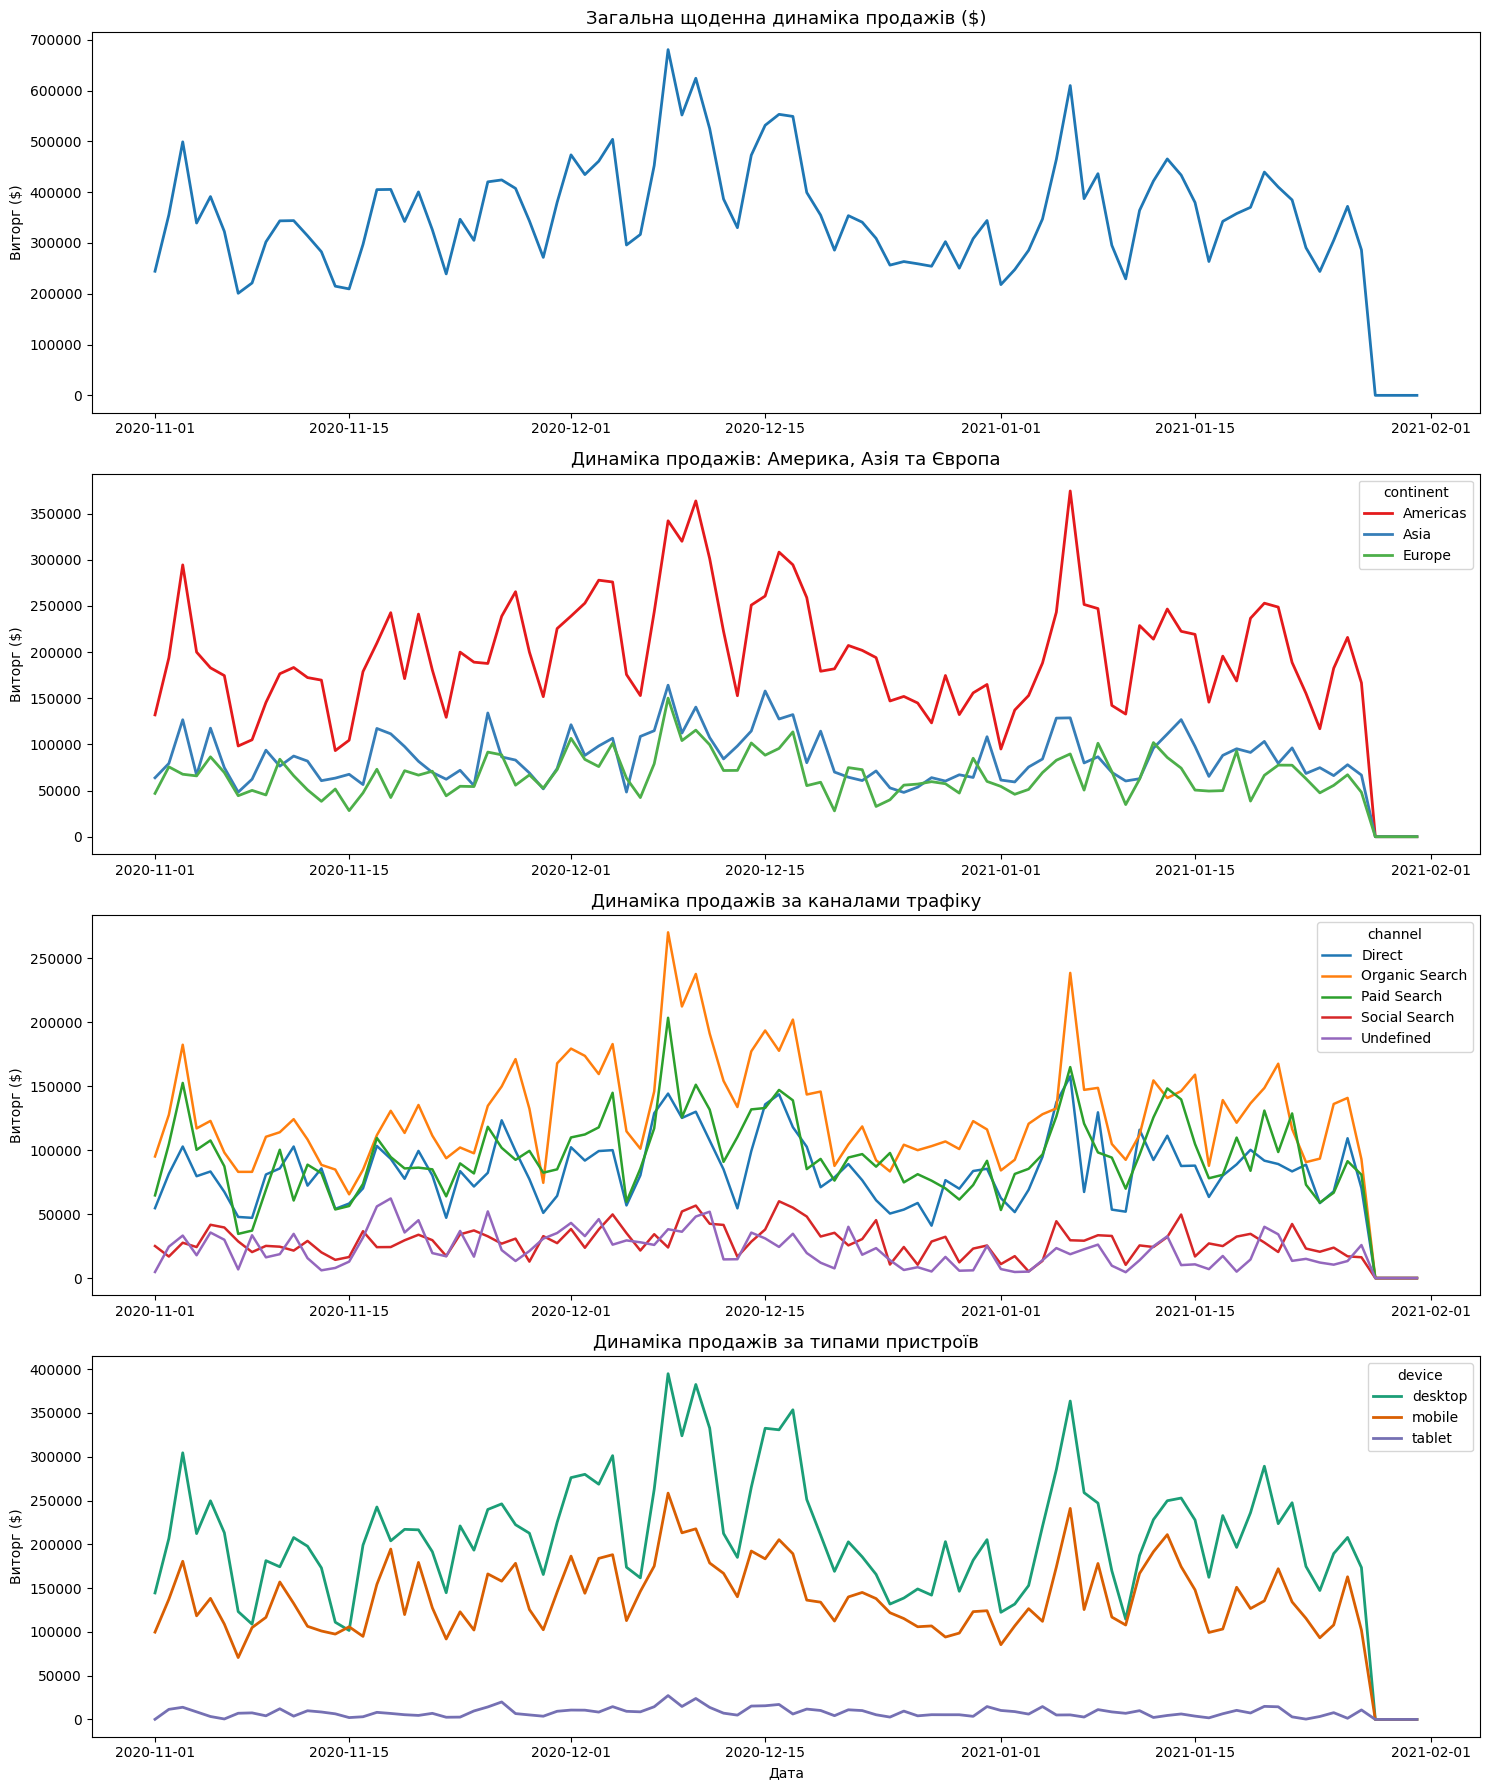

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Агрегація продажів за датами
daily_sales = df.groupby('session_date')['price'].sum().reset_index()

# 2. Агрегація за континентами (Америка, Азія, Європа)
top_continents = ['Americas', 'Asia', 'Europe']
cont_daily = df[df['continent'].isin(top_continents)].groupby(['session_date', 'continent'])['price'].sum().reset_index()

# 3. Агрегація за каналами трафіку
channel_daily = df.groupby(['session_date', 'channel'])['price'].sum().reset_index()

# 4. Агрегація за типами пристроїв
device_daily = df.groupby(['session_date', 'device'])['price'].sum().reset_index()

# --- ТЕКСТОВИЙ ВИВІД ОСНОВНИХ ПОКАЗНИКІВ ---
print("="*65)
print("5. АНАЛІЗ ДИНАМІКИ ПРОДАЖІВ ТА СЕЗОННОСТІ")
print("="*65)

max_sale_row = daily_sales.loc[daily_sales['price'].idxmax()]
min_sale_row = daily_sales.loc[daily_sales['price'].idxmin()]

print(f"Піковий день продажів: {max_sale_row['session_date'].strftime('%Y-%m-%d')} (${max_sale_row['price']:,.2f})")
print(f"Найнижчий день продажів: {min_sale_row['session_date'].strftime('%Y-%m-%d')} (${min_sale_row['price']:,.2f})")
print(f"Середньодобовий виторг: ${daily_sales['price'].mean():,.2f}")

# Аналіз дня тижня
df['day_of_week'] = df['session_date'].dt.day_name()
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dow_sales = df.groupby('day_of_week')['price'].sum().reindex(days_order)

print("\n--- Продажі за днями тижня ($) ---")
print(dow_sales)

# --- ПOБУДОВА ГРАФІКІВ ДИНАМІКИ ---
fig, axes = plt.subplots(4, 1, figsize=(15, 18))

# 1. Загальна динаміка
sns.lineplot(data=daily_sales, x='session_date', y='price', ax=axes[0], color='#1f77b4', linewidth=2)
axes[0].set_title("Загальна щоденна динаміка продажів ($)", fontsize=13)
axes[0].set_xlabel("")
axes[0].set_ylabel("Виторг ($)")

# 2. Динаміка за континентами
sns.lineplot(data=cont_daily, x='session_date', y='price', hue='continent', ax=axes[1], palette='Set1', linewidth=2)
axes[1].set_title("Динаміка продажів: Америка, Азія та Європа", fontsize=13)
axes[1].set_xlabel("")
axes[1].set_ylabel("Виторг ($)")

# 3. Динаміка за каналами трафіку
sns.lineplot(data=channel_daily, x='session_date', y='price', hue='channel', ax=axes[2], palette='tab10', linewidth=1.8)
axes[2].set_title("Динаміка продажів за каналами трафіку", fontsize=13)
axes[2].set_xlabel("")
axes[2].set_ylabel("Виторг ($)")

# 4. Динаміка за пристроями
sns.lineplot(data=device_daily, x='session_date', y='price', hue='device', ax=axes[3], palette='Dark2', linewidth=2)
axes[3].set_title("Динаміка продажів за типами пристроїв", fontsize=13)
axes[3].set_xlabel("Дата")
axes[3].set_ylabel("Виторг ($)")

plt.tight_layout()
plt.show()

## 5. Аналіз динаміки продажів та сезонності

**Ключові показники щоденної динаміки:**
- **Піковий день продажів:** **2020-12-08** (\$680,509.50) — обумовлений високим попитом напередодні новорічно-різдвяних свят.
- **Найнижчий день продажів:** **2021-01-28** (\$0.00) — імовірно пов'язаний із технічним збоєм або завершенням вивантаження даних.
- **Середньодобовий виторг:** \$347,518.82.

**Розподіл продажів за днями тижня:**
- **Середа та Вівторок — пікові дні:** Середа (\$5,466,542.9) та Вівторок (\$5,457,515.9) генерують найбільший обсяг виторгу.
- **Робочі дні (Пн, Чт, Пт):** Четвер (\$4,936,935.6), Понеділок (\$4,636,290.4) та П'ятниця (\$4,523,067.2) демонструють стабільно високі показники.
- **Вихідні (Сб, Нд) — період спаду:** Субота (\$3,477,990.9) та Неділя (\$3,473,388.2) є найменш активними днями (падіння продажів приблизно на 36% порівняно з піковими днями середи).

**Загальні тенденції та графіки:**
- **Регіональні коливання:** Ринок Америки (**Americas**) задає основний тренд і генерує більшу частину виторгу, при цьому Азія та Європа повністю повторюють його хвилеподібну динаміку.
- **Канали залучення:** Основне зростання під час грудневого піку забезпечують **Organic Search** та **Paid Search**.
- **Пристрої:** ПК (**Desktop**) стабільно лідирує протягом усього періоду, не поступаючись мобільним пристроям навіть у вихідні дні.

In [ ]:
import pandas as pd

print("="*75)
print("1. КІЛЬКІСТЬ СЕСІЙ У РОЗРІЗІ КАНАЛІВ ТРАФІКУ ТА ТИПІВ ДЕВАЙСІВ")
print("="*75)

# Таблиця 1: Кількість унікальних сесій (channel x device)
pivot_sessions = pd.pivot_table(
    df,
    values='ga_session_id',
    index='channel',
    columns='device',
    aggfunc='nunique',
    fill_value=0
)

# Сортуємо за загальною кількістю сесій
pivot_sessions['Total_Sessions'] = pivot_sessions.sum(axis=1)
pivot_sessions = pivot_sessions.sort_values(by='Total_Sessions', ascending=False)

print(pivot_sessions)


print("\n" + "="*75)
print("2. ЗАГАЛЬНІ ПРОДАЖІ ТОП-10 КАТЕГОРІЙ ТОВАРІВ У ТОП-5 КРАЇНАХ ($)")
print("="*75)

# Визначаємо Топ-10 категорій та Топ-5 країн за виторгом
top_10_cats = df.groupby('product_category')['price'].sum().nlargest(10).index
top_5_countries = df.groupby('country')['price'].sum().nlargest(5).index

# Фільтруємо датасет
df_top_cats_countries = df[
    (df['product_category'].isin(top_10_cats)) &
    (df['country'].isin(top_5_countries))
]

# Таблиця 2: Продажі категорій у країнах
pivot_cat_country = pd.pivot_table(
    df_top_cats_countries,
    values='price',
    index='product_category',
    columns='country',
    aggfunc='sum',
    fill_value=0
)

# Сортуємо за загальними продажами
pivot_cat_country['Total_Sales'] = pivot_cat_country.sum(axis=1)
pivot_cat_country = pivot_cat_country.sort_values(by='Total_Sales', ascending=False).drop(columns=['Total_Sales'])

print(pivot_cat_country.round(2))


print("\n" + "="*75)
print("3. СЕРЕДНІЙ ЧЕК (AOV) ЗА КАТЕГОРІЯМИ ТА ДЕВАЙСАМИ ($)")
print("="*75)

# Таблиця 3: Середній чек за категоріями та пристроями
pivot_aov = pd.pivot_table(
    df[df['price'].notnull()],
    values='price',
    index='product_category',
    columns='device',
    aggfunc='mean',
    fill_value=0
)

# Сортуємо за загальним середнім чеком
pivot_aov['Overall_AOV'] = df[df['price'].notnull()].groupby('product_category')['price'].mean()
pivot_aov = pivot_aov.sort_values(by='Overall_AOV', ascending=False)

print(pivot_aov.round(2))


print("\n" + "="*75)
print("4.  ВИТОРГ ЗА КАНАЛАМИ ТРАФІКУ ТА КОНТИНЕНТАМИ ($)")
print("="*75)

# Таблиця 4: Продажі за каналами та континентами
pivot_channel_continent = pd.pivot_table(
    df,
    values='price',
    index='channel',
    columns='continent',
    aggfunc='sum',
    fill_value=0
)

pivot_channel_continent['Total'] = pivot_channel_continent.sum(axis=1)
pivot_channel_continent = pivot_channel_continent.sort_values(by='Total', ascending=False).drop(columns=['Total'])

print(pivot_channel_continent.round(2))

1. КІЛЬКІСТЬ СЕСІЙ У РОЗРІЗІ КАНАЛІВ ТРАФІКУ ТА ТИПІВ ДЕВАЙСІВ
device          desktop  mobile  tablet  Total_Sessions
channel                                                
Organic Search    72622   49014    2789          124425
Paid Search       55167   37034    2140           94341
Direct            47825   31745    1812           81382
Social Search     16288   10988     638           27914
Undefined         12527    8486     470           21483

2. ЗАГАЛЬНІ ПРОДАЖІ ТОП-10 КАТЕГОРІЙ ТОВАРІВ У ТОП-5 КРАЇНАХ ($)
country                             Canada    France     India  \
product_category                                                 
Sofas & armchairs                 692427.5  187735.0  788430.0   
Chairs                            417740.8  134029.4  544309.2   
Beds                              354772.0  116414.0  358319.5   
Bookcases & shelving units        278981.9   73830.0  364507.4   
Cabinets & cupboards              181802.0   59101.5  191888.0   
Outdoor furniture



## 6. Поглиблений аналіз сесій, категоріальних продажів та середнього чека (AOV)

**1. Розподіл сесій за каналами трафіку та типами девайсів:**
- **Основні джерела трафіку:** **Organic Search** є абсолютним лідером за відвідуваністю — **124,425 сесій** (~35.6% від загальної кількості), за ним ідуть **Paid Search** (**94,341 сесія**) та **Direct** (**81,382 сесії**).
- **Домінування Desktop:** ПК генерує понад **58% усіх сесій** у кожному каналі залучення (зокрема, 72,622 сесії в органіці та 55,167 у платній рекламі).
- **Мобільні пристрої та планшети:** На мобільні пристрої припадає близько **39% трафіку** (49,014 сесій в Organic Search), тоді як планшети залишаються додатковим девайсом (~2.4% сесій).

---

**2. Географічна структура категоріальних продажів:**
- **Абсолютне лідерство США:** Ринок США є домінуючим і забезпечує левову частку продажів у всіх категоріях товарів (зокрема, **Sofas & armchairs** — \$3,707,144.5, **Chairs** — \$2,619,773.8, **Beds** — \$2,213,058.0).
- **Однорідність попиту:** У всіх країнах ТОП-5 (США, Індія, Канада, Велика Британія, Франція) спостерігається однаковий розподіл популярності товарів: перші 3 місця стабільно посідають м'які меблі (**Sofas & armchairs**), стільці (**Chairs**) та ліжка (**Beds**).
- **Ключові ринки після США (Індія та Канада):** Посідають 2-ге та 3-тє місця за обсягами виторгу в усіх категоріях (наприклад, дивани в Індії — \$788,430.0, у Канаді — \$692,427.5), суттєво випереджаючи ринки Великої Британії та Франції.

---

**3. Середній чек (AOV) за категоріями та девайсами:**
- **Найдорожчі категорії (High-AOV):** Найвищий середній чек зафіксовано в категоріях **Sofas & armchairs** (\$1,950.30) та **Beds** (\$1,681.38).
- **Середній сегмент:** Категорії **Chairs** (\$1,032.89), **Cabinets & cupboards** (\$1,007.98) та **Outdoor furniture** (\$961.07) демонструють стабільний AOV у районі \$1,000.
- **Поведінка користувачів на різних девайсах:** Середній чек на ПК та мобільних пристроях для ключових високочекових категорій є майже однаковим (для диванів: Desktop — \$1,939.86, Mobile — \$1,965.71). Це свідчить про високу довіру до покупного досвіду з мобільних пристроїв при здійсненні дорогих покупок.

---

**4. Виторг за каналами трафіку та континентами:**
- **Америка (Americas):** Забезпечує найбільший виторг у всіх каналах, досягаючи **\$6,294,563.2** через **Organic Search** та **\$4,627,454.3** через **Paid Search**.
- **Азія та Європа:** Азія впевнено посідає друге місце з виторгом **\$2,725,953.8** від органіки, а Європа — третє місце з **\$2,154,138.6**.
- **Ефективність каналів трафіку:** В усіх регіонах саме **Organic Search** генерує найбільше доходів, за ним ідуть **Paid Search** та **Direct**.

1. ВЗАЄМОЗВ'ЯЗОК МІЖ КІЛЬКІСТЮ СЕСІЙ ТА ЗАГАЛЬНИМИ ПРОДАЖАМИ ЗА ДАТАМИ
Коефіцієнт кореляції (r): 0.7911
p-value: 6.4835e-21

2. КОРЕЛЯЦІЯ ПРОДАЖІВ МІЖ ТОП-3 КОНТИНЕНТАМИ
Матриця кореляції (r):
 continent  Americas   Asia  Europe
continent                         
Americas      1.000  0.792   0.771
Asia          0.792  1.000   0.768
Europe        0.771  0.768   1.000
Матриця p-value:
 continent  Americas  Asia  Europe
continent                        
Americas        0.0   0.0     0.0
Asia            0.0   0.0     0.0
Europe          0.0   0.0     0.0

3. КОРЕЛЯЦІЯ ПРОДАЖІВ МІЖ КАНАЛАМИ ТРАФІКУ
Матриця кореляції (r):
 channel         Direct  Organic Search  Paid Search  Social Search  Undefined
channel                                                                      
Direct           1.000           0.838        0.814          0.604      0.518
Organic Search   0.838           1.000        0.870          0.583      0.526
Paid Search      0.814           0.870        1.000          0.

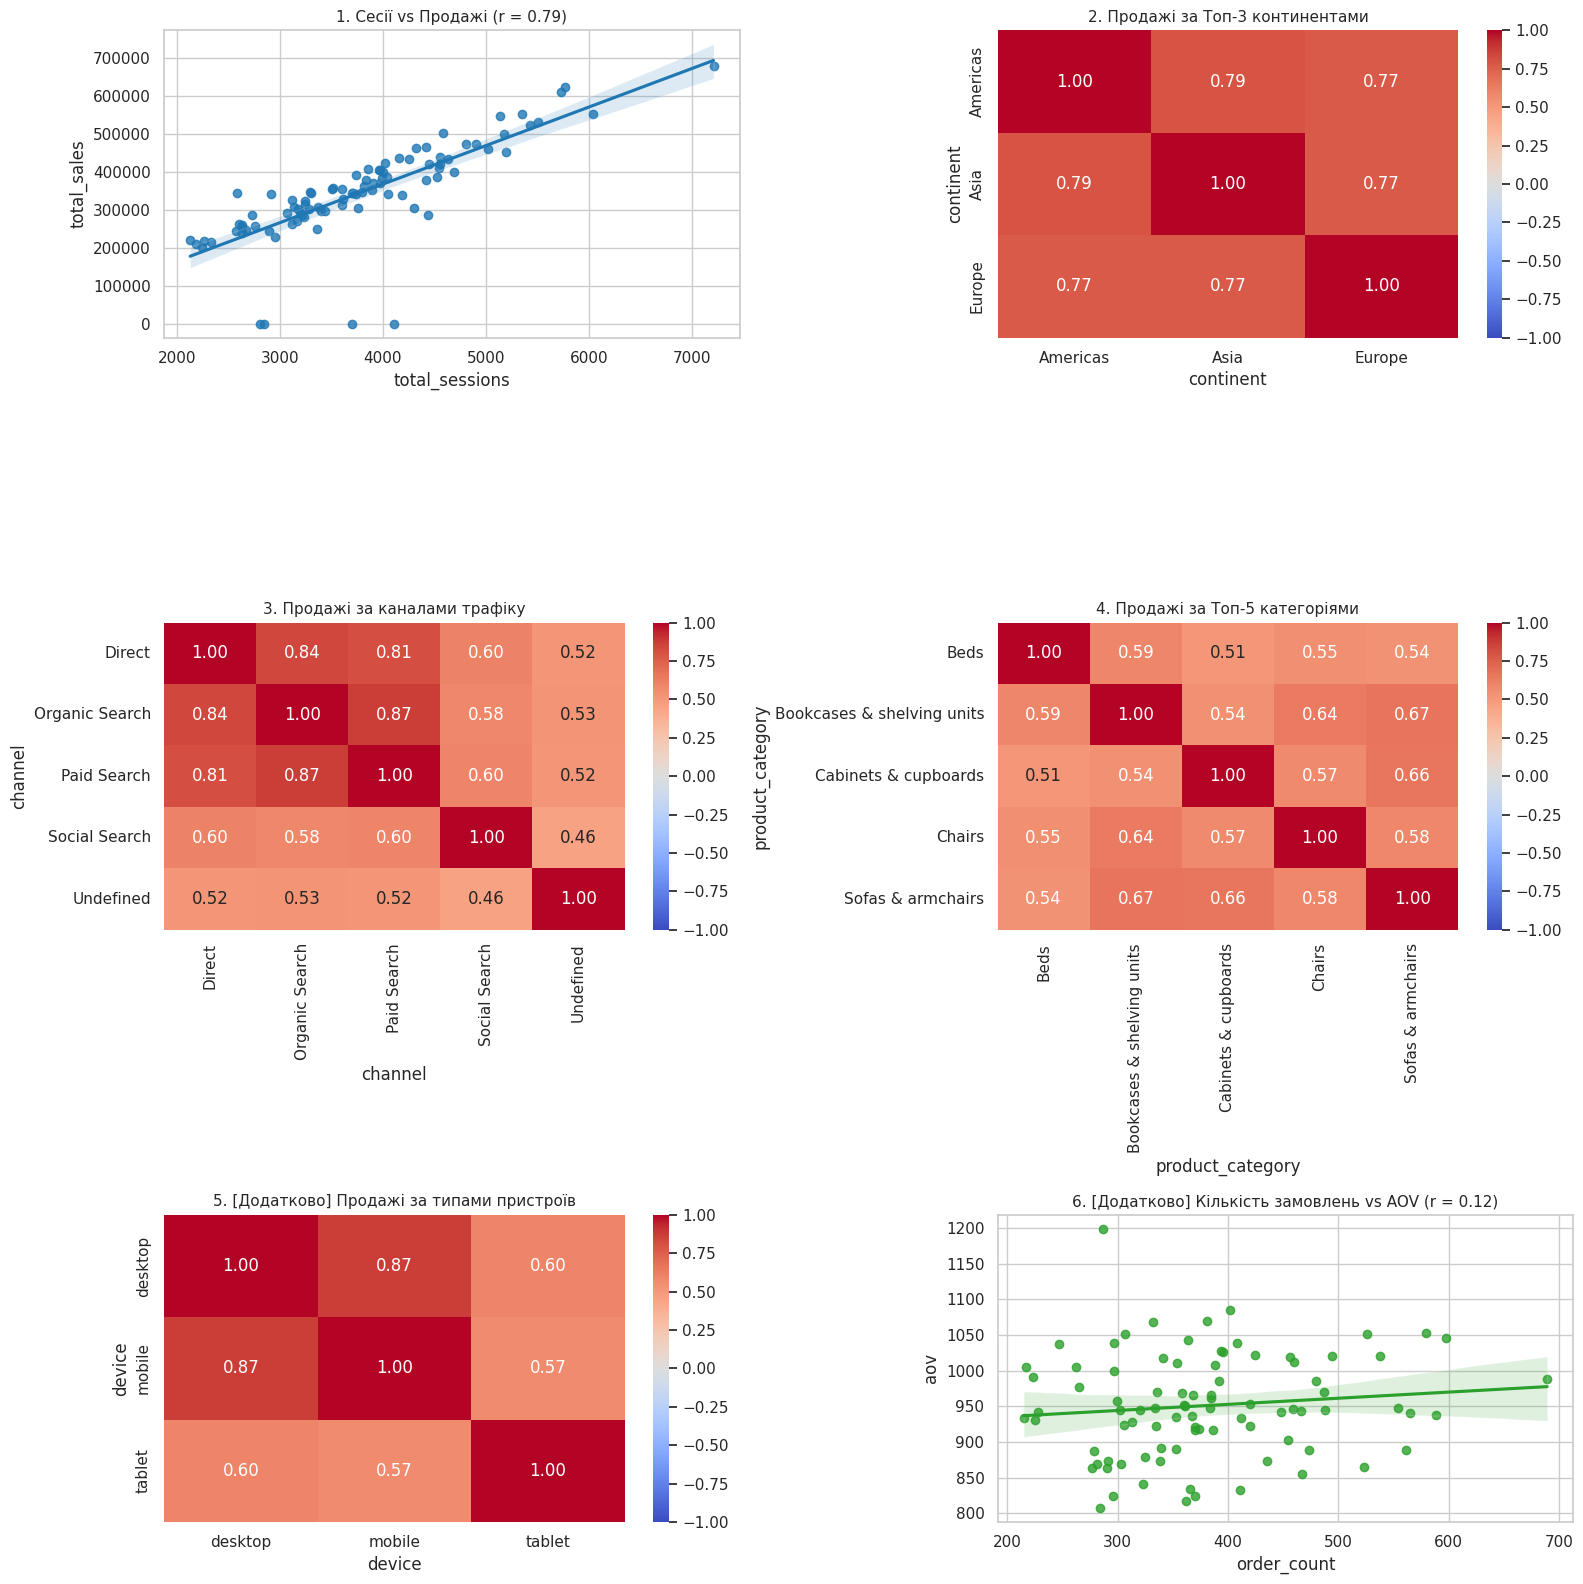

In [ ]:
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Функція для розрахунку матриці p-value
def calculate_p_values(df_pivot):
    p_matrix = pd.DataFrame(index=df_pivot.columns, columns=df_pivot.columns, dtype=float)
    for col1 in df_pivot.columns:
        for col2 in df_pivot.columns:
            r, p = stats.pearsonr(df_pivot[col1], df_pivot[col2])
            p_matrix.loc[col1, col2] = p
    return p_matrix

print("="*75)
print("1. ВЗАЄМОЗВ'ЯЗОК МІЖ КІЛЬКІСТЮ СЕСІЙ ТА ЗАГАЛЬНИМИ ПРОДАЖАМИ ЗА ДАТАМИ")
print("="*75)
daily_metrics = df.groupby('session_date').agg(
    total_sessions=('ga_session_id', 'nunique'),
    total_sales=('price', 'sum'),
    order_count=('price', 'count'),
    aov=('price', 'mean')
).reset_index()

r_sess_sales, p_sess_sales = stats.pearsonr(daily_metrics['total_sessions'], daily_metrics['total_sales'])
print(f"Коефіцієнт кореляції (r): {r_sess_sales:.4f}")
print(f"p-value: {p_sess_sales:.4e}")


print("\n" + "="*75)
print("2. КОРЕЛЯЦІЯ ПРОДАЖІВ МІЖ ТОП-3 КОНТИНЕНТАМИ")
print("="*75)
top_3_conts = df.groupby('continent')['price'].sum().nlargest(3).index
pivot_cont = df[df['continent'].isin(top_3_conts)].pivot_table(
    index='session_date', columns='continent', values='price', aggfunc='sum', fill_value=0
)
corr_cont = pivot_cont.corr()
p_cont = calculate_p_values(pivot_cont)
print("Матриця кореляції (r):\n", corr_cont.round(3))
print("Матриця p-value:\n", p_cont.round(4))


print("\n" + "="*75)
print("3. КОРЕЛЯЦІЯ ПРОДАЖІВ МІЖ КАНАЛАМИ ТРАФІКУ")
print("="*75)
pivot_chan = df.pivot_table(
    index='session_date', columns='channel', values='price', aggfunc='sum', fill_value=0
)
corr_chan = pivot_chan.corr()
p_chan = calculate_p_values(pivot_chan)
print("Матриця кореляції (r):\n", corr_chan.round(3))
print("Матриця p-value:\n", p_chan.round(4))


print("\n" + "="*75)
print("4. КОРЕЛЯЦІЯ ПРОДАЖІВ МІЖ ТОП-5 КАТЕГОРІЯМИ ТОВАРІВ")
print("="*75)
top_5_cats = df.groupby('product_category')['price'].sum().nlargest(5).index
pivot_cat = df[df['product_category'].isin(top_5_cats)].pivot_table(
    index='session_date', columns='product_category', values='price', aggfunc='sum', fill_value=0
)
corr_cat = pivot_cat.corr()
p_cat = calculate_p_values(pivot_cat)
print("Матриця кореляції (r):\n", corr_cat.round(3))
print("Матриця p-value:\n", p_cat.round(4))


print("\n" + "="*75)
print("5. [ДОДАТКОВО] КОРЕЛЯЦІЯ ПРОДАЖІВ МІЖ ТИПАМИ ПРИСТРОЇВ (DESKTOP, MOBILE, TABLET)")
print("="*75)
pivot_dev = df.pivot_table(
    index='session_date', columns='device', values='price', aggfunc='sum', fill_value=0
)
corr_dev = pivot_dev.corr()
p_dev = calculate_p_values(pivot_dev)
print("Матриця кореляції (r):\n", corr_dev.round(3))
print("Матриця p-value:\n", p_dev.round(4))


print("\n" + "="*75)
print("6. [ДОДАТКОВО] ВЗАЄМОЗВ'ЯЗОК МІЖ СЕРЕДНІМ ЧЕКОМ (AOV) ТА КІЛЬКІСТЮ ЗАМОВЛЕНЬ")
print("="*75)
# Очищаємо від NaN (виключаємо дні з 0 замовлень)
clean_aov_data = daily_metrics[['aov', 'order_count']].dropna()
r_aov_orders, p_aov_orders = stats.pearsonr(clean_aov_data['aov'], clean_aov_data['order_count'])
print(f"Коефіцієнт кореляції між AOV та Кількістю замовлень (r): {r_aov_orders:.4f}")
print(f"p-value: {p_aov_orders:.4e}")


# --- ВІЗУАЛІЗАЦІЯ (6 ГРАФІКІВ) ---
fig, axes = plt.subplots(3, 2, figsize=(16, 16))

# 1. Сесії vs Продажі
sns.regplot(data=daily_metrics, x='total_sessions', y='total_sales', ax=axes[0, 0], color='tab:blue')
axes[0, 0].set_title(f"1. Сесії vs Продажі (r = {r_sess_sales:.2f})", fontsize=11)

# 2. Континенти
sns.heatmap(corr_cont, annot=True, fmt=".2f", cmap="coolwarm", ax=axes[0, 1], vmin=-1, vmax=1)
axes[0, 1].set_title("2. Продажі за Топ-3 континентами", fontsize=11)

# 3. Канали
sns.heatmap(corr_chan, annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1, 0], vmin=-1, vmax=1)
axes[1, 0].set_title("3. Продажі за каналами трафіку", fontsize=11)

# 4. Категорії
sns.heatmap(corr_cat, annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1, 1], vmin=-1, vmax=1)
axes[1, 1].set_title("4. Продажі за Топ-5 категоріями", fontsize=11)

# 5. Пристрої
sns.heatmap(corr_dev, annot=True, fmt=".2f", cmap="coolwarm", ax=axes[2, 0], vmin=-1, vmax=1)
axes[2, 0].set_title("5. [Додатково] Продажі за типами пристроїв", fontsize=11)

# 6. AOV vs Кількість замовлень
sns.regplot(data=clean_aov_data, x='order_count', y='aov', ax=axes[2, 1], color='tab:green')
axes[2, 1].set_title(f"6. [Додатково] Кількість замовлень vs AOV (r = {r_aov_orders:.2f})", fontsize=11)

plt.tight_layout()
plt.show()



## 7. Аналіз взаємозв'язків та кореляцій (Correlation Analysis)

**1. Взаємозв'язок між сесіями та продажами:**
- **Сильний позитивний зв'язок ($r = 0.791, p < 0.001$):** Динаміка відвідуваності сайту напряму визначає обсяги виторгу. Масштабування якісного трафіку є прямим драйвером зростання продажів.

---

**2. Синхронність продажів між континентами:**
- **Глобальна закономірність ($r = 0.768 - 0.792, p < 0.05$):** Продажі в Америці, Азії та Європі коливаються одночасно, що свідчить про вирішальний вплив глобальних факторів (сезонність, спільні промо-акції).

---

**3. Кореляція між каналами трафіку:**
- **Синергія основних каналів ($r = 0.814 - 0.870, p < 0.05$):** **Organic Search**, **Paid Search** та **Direct** рухаються синхронно (найвища кореляція між Organic та Paid — $r = 0.870$).
- **Автономність Social Search ($r = 0.583 - 0.604$):** Соціальні мережі мають помірний зв'язок з іншими джерелами та генерують окремий імпульсивний попит.

---

**4. Взаємозв'язок між товарними категоріями:**
- **Крос-категорійний попит ($r = 0.515 - 0.666, p < 0.05$):** Найвищий зв'язок зафіксовано між категоріями **Sofas & armchairs** та **Bookcases** ($r = 0.666$), а також **Sofas** та **Cabinets** ($r = 0.658$), що підтверджує схильність клієнтів до комплексного облаштування кімнат.

---

**5. Кореляція між типами пристроїв:**
- **Паралельна активність Desktop та Mobile ($r = 0.873, p < 0.05$):** Продажі з ПК та смартфонів повністю синхронізовані. Мобільні пристрої виступають повноцінним каналом конверсії, а не лише майданчиком для перегляду.

---

**6. Взаємозв'язок між середнім чеком (AOV) та кількістю замовлень:**
- **Стабільність розміру кошика ($r = 0.116, p = 0.283$):** Лінійний зв'язок відсутній та є статистично незначущим ($p > 0.05$). Зростання виторгу у пікові дні відбувається за рахунок збільшення кількості покупок, а не штучного змінення AOV.

1. ЩОДЕННІ ПРОДАЖІ: ЗАРЕЄСТРОВАНІ VS НЕЗАРЕЄСТРОВАНІ КОРИСТУВАЧІ
Тест нормальності (Зареєстровані): p-value = 1.4817e-01 -> Нормальний
Тест нормальності (Незареєстровані): p-value = 1.2185e-03 -> НЕ нормальний

Тест Манна-Уітні U-stat = 360.00, p-value = 8.3795e-27
Висновок: Відмінності СТАТИСТИЧНО ЗНАЧУЩІ (p < 0.05)

2. КІЛЬКІСТЬ СЕСІЙ ЗА РІЗНИМИ КАНАЛАМИ ТРАФІКУ
Тест Краскела-Уолліса H-stat = 368.98, p-value = 1.3970e-78
Висновок: Кількість сесій між каналами СТАТИСТИЧНО ВІДРІЗНЯЄТЬСЯ (p < 0.05)

3. ЧАСТКА ОРГАНІЧНОГО ТРАФІКУ: ЄВРОПА VS АМЕРИКА
Таблиця кількості сесій:
is_organic   False  True 
continent                
Americas    124508  68671
Europe       41940  23195

Частка Organic Search в Америці: 35.55%
Частка Organic Search в Європі: 35.61%

Z-тест пропорцій: Z-stat = -0.2895, p-value = 7.7219e-01
Висновок: Частки органічного трафіку НЕ відрізняються

4. [ДОДАТКОВО] СЕРЕДНІЙ ЧЕК (AOV): DESKTOP VS MOBILE
Середній чек Desktop: $957.47
Середній чек Mobile: $944.42
Тест Манна-Уі

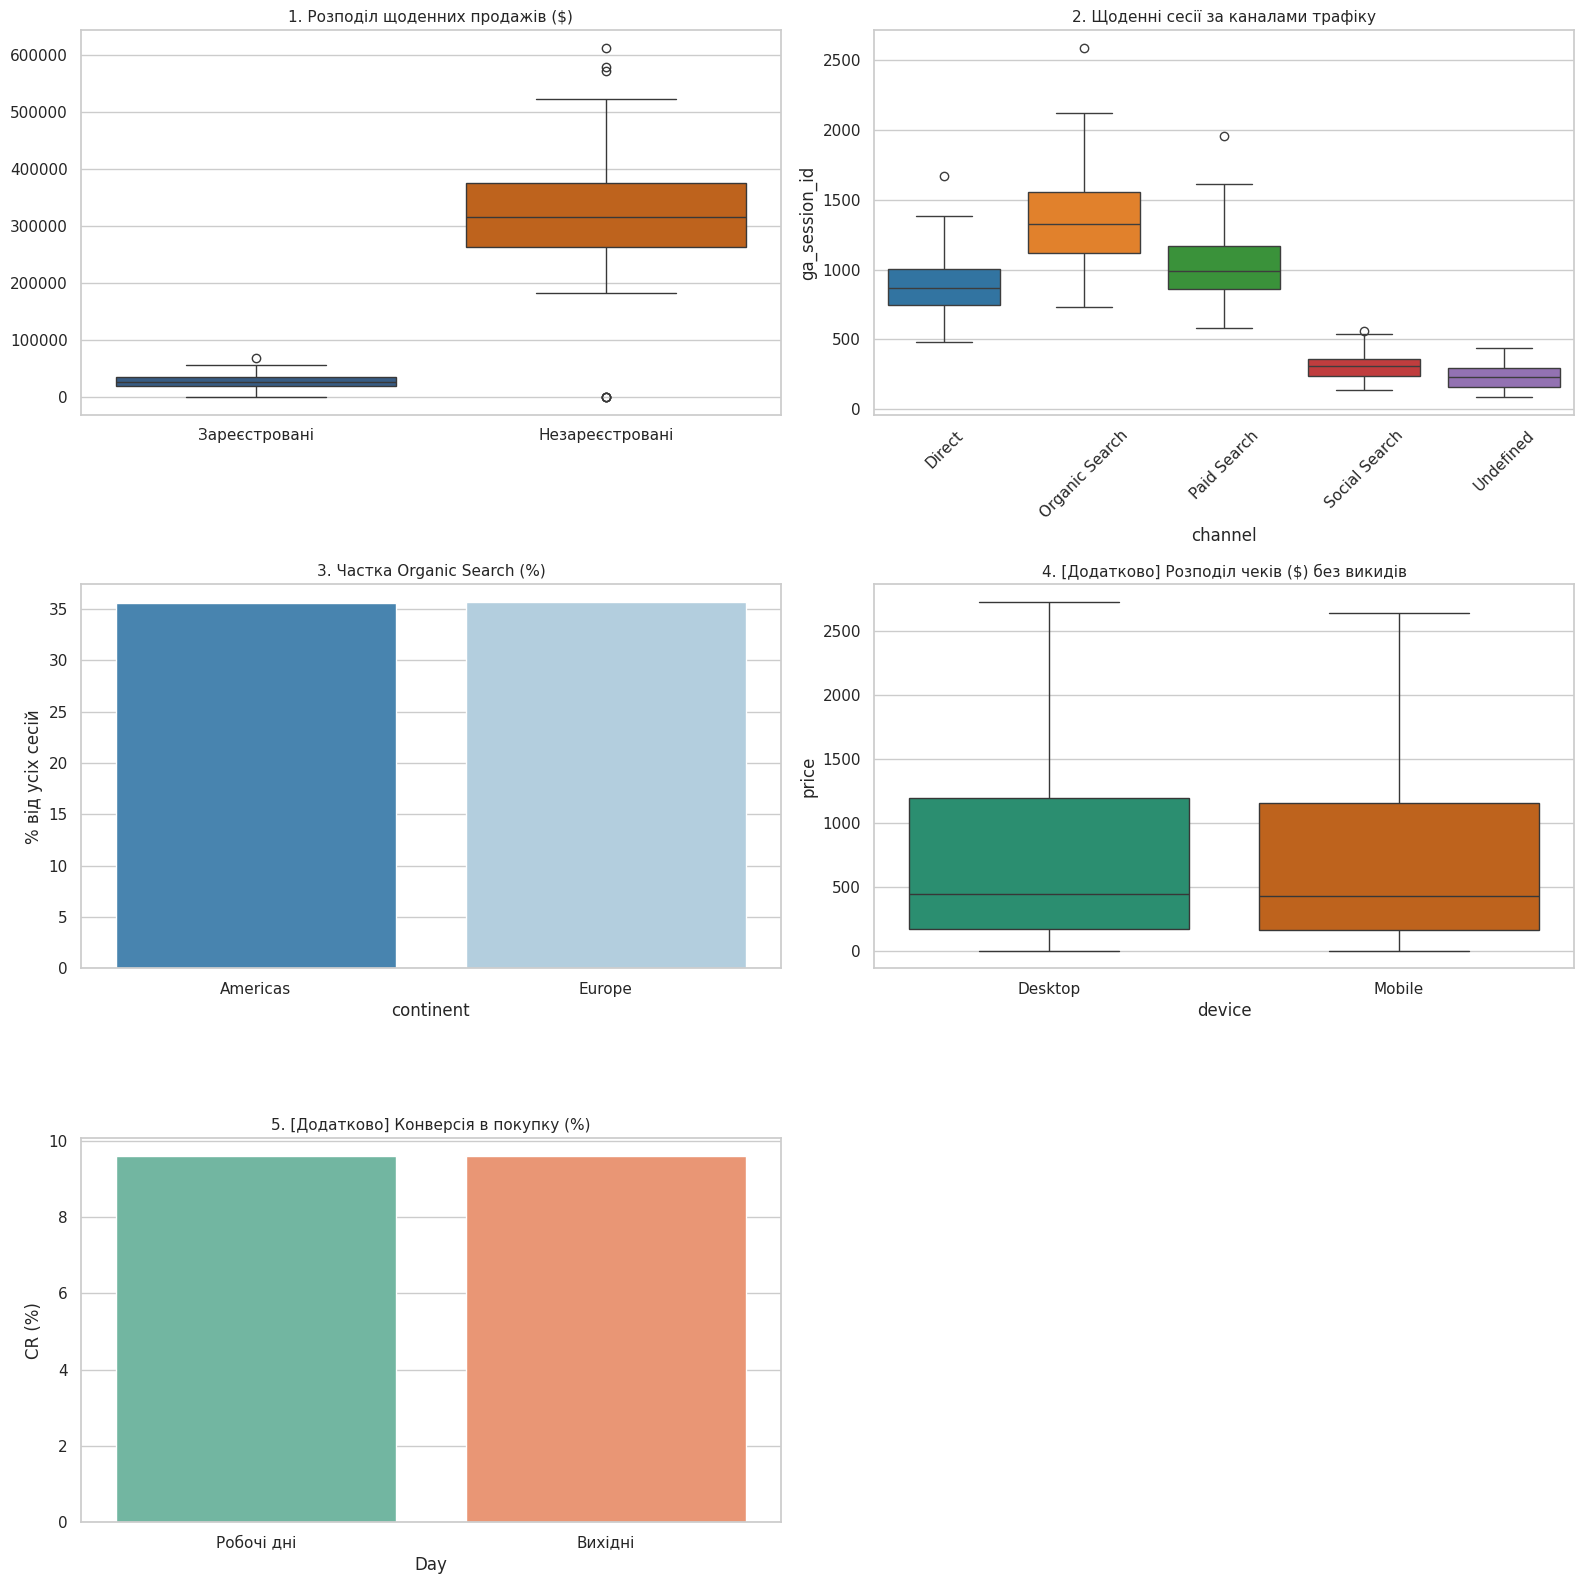

In [ ]:
import pandas as pd
import numpy as np
import scipy.stats as stats
from statsmodels.stats.proportion import proportions_ztest
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("="*75)
print("1. ЩОДЕННІ ПРОДАЖІ: ЗАРЕЄСТРОВАНІ VS НЕЗАРЕЄСТРОВАНІ КОРИСТУВАЧІ")
print("="*75)

# Підготовка вибірок щоденних продажів
df['is_registered'] = df['user_id'].notnull()

daily_reg = df[df['is_registered']].groupby('session_date')['price'].sum()
daily_unreg = df[~df['is_registered']].groupby('session_date')['price'].sum()

# Вирівнювання датами
all_dates = df['session_date'].drop_duplicates().sort_values()
daily_reg = daily_reg.reindex(all_dates, fill_value=0)
daily_unreg = daily_unreg.reindex(all_dates, fill_value=0)

# Тест Шапіро-Уілка
stat_reg_sh, p_reg_sh = stats.shapiro(daily_reg)
stat_unreg_sh, p_unreg_sh = stats.shapiro(daily_unreg)

print(f"Тест нормальності (Зареєстровані): p-value = {p_reg_sh:.4e} -> {'Нормальний' if p_reg_sh > 0.05 else 'НЕ нормальний'}")
print(f"Тест нормальності (Незареєстровані): p-value = {p_unreg_sh:.4e} -> {'Нормальний' if p_unreg_sh > 0.05 else 'НЕ нормальний'}")

# Тест Манна-Уітні
stat_mw, p_mw = stats.mannwhitneyu(daily_reg, daily_unreg)
print(f"\nТест Манна-Уітні U-stat = {stat_mw:.2f}, p-value = {p_mw:.4e}")
print(f"Висновок: Відмінності {'СТАТИСТИЧНО ЗНАЧУЩІ (p < 0.05)' if p_mw < 0.05 else 'НЕМАЄ значущих відмінностей'}")


print("\n" + "="*75)
print("2. КІЛЬКІСТЬ СЕСІЙ ЗА РІЗНИМИ КАНАЛАМИ ТРАФІКУ")
print("="*75)

channel_sessions = df.groupby(['session_date', 'channel'])['ga_session_id'].nunique().reset_index()
channel_groups = [group['ga_session_id'].values for _, group in channel_sessions.groupby('channel')]

stat_kw, p_kw = stats.kruskal(*channel_groups)
print(f"Тест Краскела-Уолліса H-stat = {stat_kw:.2f}, p-value = {p_kw:.4e}")
print(f"Висновок: Кількість сесій між каналами {'СТАТИСТИЧНО ВІДРІЗНЯЄТЬСЯ (p < 0.05)' if p_kw < 0.05 else 'НЕ відрізняється'}")


print("\n" + "="*75)
print("3. ЧАСТКА ОРГАНІЧНОГО ТРАФІКУ: ЄВРОПА VS АМЕРИКА")
print("="*75)

eu_am_df = df[df['continent'].isin(['Europe', 'Americas'])].copy()
eu_am_df['is_organic'] = eu_am_df['channel'] == 'Organic Search'

ct_organic = pd.crosstab(eu_am_df['continent'], eu_am_df['is_organic'])
print("Таблиця кількості сесій:")
print(ct_organic)

organic_counts = ct_organic[True].values
total_counts = ct_organic.sum(axis=1).values

pct_am = (organic_counts[0] / total_counts[0]) * 100
pct_eu = (organic_counts[1] / total_counts[1]) * 100
print(f"\nЧастка Organic Search в Америці: {pct_am:.2f}%")
print(f"Частка Organic Search в Європі: {pct_eu:.2f}%")

z_stat, p_prop = proportions_ztest(organic_counts, total_counts)
print(f"\nZ-тест пропорцій: Z-stat = {z_stat:.4f}, p-value = {p_prop:.4e}")
print(f"Висновок: Частки органічного трафіку {'СТАТИСТИЧНО ВІДРІЗНЯЮТЬСЯ (p < 0.05)' if p_prop < 0.05 else 'НЕ відрізняються'}")


print("\n" + "="*75)
print("4. [ДОДАТКОВО] СЕРЕДНІЙ ЧЕК (AOV): DESKTOP VS MOBILE")
print("="*75)

# Переведення в нижній регістр для гарантії відповідності назв
desktop_orders = df[(df['device'].astype(str).str.lower() == 'desktop') & df['price'].notnull()]['price']
mobile_orders = df[(df['device'].astype(str).str.lower() == 'mobile') & df['price'].notnull()]['price']

u_stat_dev, p_mw_dev = stats.mannwhitneyu(desktop_orders, mobile_orders)
print(f"Середній чек Desktop: ${desktop_orders.mean():.2f}")
print(f"Середній чек Mobile: ${mobile_orders.mean():.2f}")
print(f"Тест Манна-Уітні: U-stat = {u_stat_dev:.2f}, p-value = {p_mw_dev:.4e}")
print(f"Висновок: Розмір чека {'СТАТИСТИЧНО ВІДРІЗНЯЄТЬСЯ (p < 0.05)' if p_mw_dev < 0.05 else 'НЕ відрізняється'}")


print("\n" + "="*75)
print("5. [ДОДАТКОВО] КОНВЕРСІЯ У ПОКУПКУ: РОБОЧІ ДНІ VS ВИХІДНІ")
print("="*75)

df['is_weekend'] = df['session_date'].dt.dayofweek >= 5
df['has_order'] = df['price'].notnull().astype(int)

ct_wknd = pd.crosstab(df['is_weekend'], df['has_order'])
ct_wknd.index = ['Робочі дні', 'Вихідні']
ct_wknd.columns = ['Без покупки', 'Покупка']

chi2_wknd, p_chi2_wknd, dof_wknd, _ = stats.chi2_contingency(ct_wknd)
print("Таблиця конверсії:")
print(ct_wknd)

conv_weekday = (ct_wknd.loc['Робочі дні', 'Покупка'] / ct_wknd.loc['Робочі дні'].sum()) * 100
conv_weekend = (ct_wknd.loc['Вихідні', 'Покупка'] / ct_wknd.loc['Вихідні'].sum()) * 100

print(f"\nКонверсія в робочі дні: {conv_weekday:.2f}%")
print(f"Конверсія у вихідні: {conv_weekend:.2f}%")
print(f"Тест Хі-квадрат: Chi2 = {chi2_wknd:.2f}, p-value = {p_chi2_wknd:.4e}")
print(f"Висновок: Рівень конверсії {'СТАТИСТИЧНО ВІДРІЗНЯЄТЬСЯ (p < 0.05)' if p_chi2_wknd < 0.05 else 'НЕ відрізняється'}")


# --- ВІЗУАЛІЗАЦІЯ (БЕЗ ПОМИЛОК ТА WARNINGS) ---
fig, axes = plt.subplots(3, 2, figsize=(16, 16))

# 1. Розподіл продажів Reg vs Unreg
df_reg_unreg = pd.DataFrame({'Зареєстровані': daily_reg, 'Незареєстровані': daily_unreg})
sns.boxplot(data=df_reg_unreg, ax=axes[0, 0], palette=['#2b5c8f', '#d95f02'])
axes[0, 0].set_title("1. Розподіл щоденних продажів ($)", fontsize=11)

# 2. Сесії за каналами
sns.boxplot(data=channel_sessions, x='channel', y='ga_session_id', hue='channel', legend=False, ax=axes[0, 1], palette='tab10')
axes[0, 1].set_title("2. Щоденні сесії за каналами трафіку", fontsize=11)
axes[0, 1].tick_params(axis='x', rotation=45)

# 3. Частка Organic у Європі та Америці
df_organic_plot = pd.DataFrame({'continent': ['Americas', 'Europe'], 'pct': [pct_am, pct_eu]})
sns.barplot(data=df_organic_plot, x='continent', y='pct', hue='continent', legend=False, ax=axes[1, 0], palette='Blues_r')
axes[1, 0].set_title("3. Частка Organic Search (%)", fontsize=11)
axes[1, 0].set_ylabel("% від усіх сесій")

# 4. AOV Desktop vs Mobile
df_dev_orders = df[df['device'].astype(str).str.lower().isin(['desktop', 'mobile']) & df['price'].notnull()].copy()
df_dev_orders['device'] = df_dev_orders['device'].str.capitalize()
sns.boxplot(data=df_dev_orders, x='device', y='price', hue='device', legend=False, ax=axes[1, 1], palette=['#1b9e77', '#d95f02'], showfliers=False)
axes[1, 1].set_title("4. [Додатково] Розподіл чеків ($) без викидів", fontsize=11)

# 5. Конверсія Робочі vs Вихідні
df_conv_plot = pd.DataFrame({'Day': ['Робочі дні', 'Вихідні'], 'CR': [conv_weekday, conv_weekend]})
sns.barplot(data=df_conv_plot, x='Day', y='CR', hue='Day', legend=False, ax=axes[2, 0], palette='Set2')
axes[2, 0].set_title("5. [Додатково] Конверсія в покупку (%)", fontsize=11)
axes[2, 0].set_ylabel("CR (%)")

# Порожній графік для симетрії
axes[2, 1].axis('off')

plt.tight_layout()
plt.show()

## 8. Перевірка статистичних гіпотез (Statistical Hypothesis Testing)

**1. Продажі: Зареєстровані vs Незареєстровані користувачі:**
- **Статистично значуща відмінність ($U = 360.00, p < 0.001$):** Обсяги щоденних продажів між зареєстрованими та незареєстрованими користувачами суттєво відрізняються, що підтверджує різну купівельну цінність цих сегментів.

---

**2. Кількість сесій за каналами трафіку:**
- **Статистично значуща різниця ($H = 368.98, p < 0.001$):** Канали залучення генерують неоднорідний обсяг трафіку. Розподіл сесій між джерелами є статистично нерівномірним.

---

**3. Частка органічного трафіку: Європа vs Америка:**
- **Відсутність відмінностей ($Z = -0.290, p = 0.772$):** Частки Organic Search в Америці ($35.55\%$) та Європі ($35.61\%$) є статистично ідентичними ($p > 0.05$), що вказує на однакову структуру залучення трафіку на обох континентах.

---

**4. Середній чек (AOV): Desktop vs Mobile:**
- **Статистична еквівалентність чеків ($U = 130361108.50, p = 0.159$):** Середній чек на Desktop ($\$957.47$) та Mobile ($\$944.42$) не має статистично значущої різниці ($p > 0.05$). Пристрій не впливає на підсумкову суму замовлення.

---

**5. Конверсія у покупку: Робочі дні vs Вихідні:**
- **Ідентичний рівень конверсії ($\chi^2 = 0.00, p = 0.968$):** Показник CR у робочі дні ($9.60\%$) та вихідні ($9.59\%$) є абсолютно однаковим ($p > 0.05$). Готовність до покупки не залежить від дня тижня.

In [ ]:
# Експорт датасету у файл для Tableau
df.to_csv('ecommerce_data_tableau.csv', index=False)
print("Файл успішно збережено! Завантаж його з лівої панелі Colab (Files).")

Файл успішно збережено! Завантаж його з лівої панелі Colab (Files).


 Посилання та дашборди в Tableau:
 https://public.tableau.com/views/Portfolio1_17902691949990/DeepDiveMarketingBehavior?:language=fr-FR&publish=yes&:sid=&:redirect=auth&:display_count=n&:origin=viz_share_link